In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"

DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully!")
print("Amazon Sentiment Analysis project is ready.")

Libraries imported successfully!
Amazon Sentiment Analysis project is ready.


In [30]:
DATA_FILE = DATA_DIR / "amazon_reviews.csv"

df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (4915, 12)
Column names: ['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound']


,Unnamed: 0,reviewerName,overall,reviewText,reviewTime,day_diff,helpful_yes,helpful_no,total_vote,score_pos_neg_diff,score_average_rating,wilson_lower_bound
0,0,NaN,4.0,No issues.,2014-07-23,138,0,0,0,0,0.0,0.0
1,1,0mie,5.0,"Purchased this for my device, it worked as adv...",2013-10-25,409,0,0,0,0,0.0,0.0
2,2,1K3,4.0,it works as expected. I should have sprung for...,2012-12-23,715,0,0,0,0,0.0,0.0
3,3,1m2,5.0,This think has worked out great.Had a diff. br...,2013-11-21,382,0,0,0,0,0.0,0.0
4,4,2&amp;1/2Men,5.0,"Bought it with Retail Packaging, arrived legit...",2013-07-13,513,0,0,0,0,0.0,0.0


In [31]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nRating distribution:")
display(df["overall"].value_counts().sort_index())

Dataset shape: (4915, 12)

Missing values:


Unnamed: 0              0
reviewerName            1
overall                 0
reviewText              1
reviewTime              0
day_diff                0
helpful_yes             0
helpful_no              0
total_vote              0
score_pos_neg_diff      0
score_average_rating    0
wilson_lower_bound      0
dtype: int64


Duplicate rows: 0

Rating distribution:


overall
1.0     244
2.0      80
3.0     142
4.0     527
5.0    3922
Name: count, dtype: int64

In [32]:
sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)

plt.title("Amazon Reviews Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "sentiment_distribution.png", dpi=150)
plt.show()

display(sentiment_counts.rename_axis("Sentiment").reset_index(name="Count"))

KeyError: 'sentiment'

In [ ]:
print(df.columns.tolist())

['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound']


In [ ]:
df = df.dropna(subset=["reviewText", "overall"]).copy()
df["overall"] = pd.to_numeric(df["overall"], errors="coerce")
df = df.dropna(subset=["overall"])
df = df[df["overall"].between(1, 5)]
df["reviewText"] = df["reviewText"].astype(str).str.strip()
df = df[df["reviewText"] != ""]
df = df.drop_duplicates(subset=["reviewText"])

df["sentiment"] = df["overall"].apply(
    lambda rating: "positive" if rating >= 4
    else "negative" if rating <= 2
    else "neutral"
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df[["reviewText", "overall", "sentiment"]].head())

Dataset shape: (4912, 13)
Columns: ['Unnamed: 0', 'reviewerName', 'overall', 'reviewText', 'reviewTime', 'day_diff', 'helpful_yes', 'helpful_no', 'total_vote', 'score_pos_neg_diff', 'score_average_rating', 'wilson_lower_bound', 'sentiment']


,reviewText,overall,sentiment
0,No issues.,4.0,positive
1,"Purchased this for my device, it worked as adv...",5.0,positive
2,it works as expected. I should have sprung for...,4.0,positive
3,This think has worked out great.Had a diff. br...,5.0,positive
4,"Bought it with Retail Packaging, arrived legit...",5.0,positive


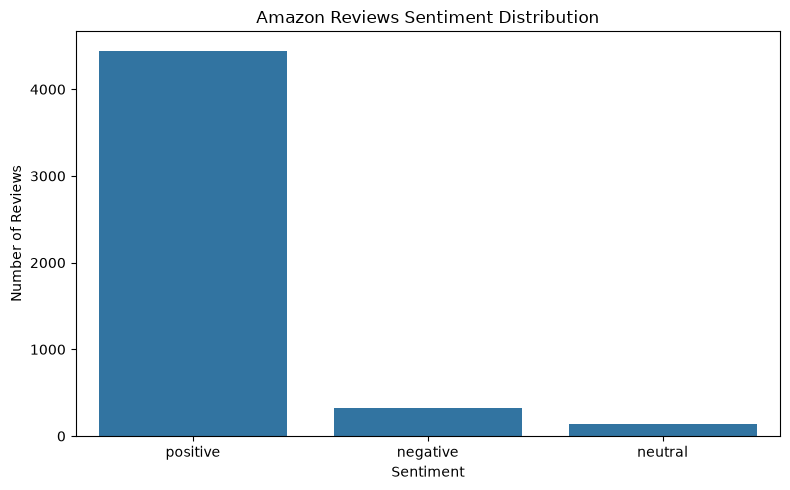

sentiment
positive    4446
negative     324
neutral      142
Name: count, dtype: int64

In [ ]:
sentiment_counts = df["sentiment"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)
plt.title("Amazon Reviews Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sentiment_distribution.png", dpi=150)
plt.show()

display(sentiment_counts)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

X = df["reviewText"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Model training completed!")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model training completed!
Accuracy: 0.8973

Classification Report:
              precision    recall  f1-score   support

    negative       0.56      0.72      0.63        65
     neutral       0.06      0.07      0.07        28
    positive       0.96      0.94      0.95       890

    accuracy                           0.90       983
   macro avg       0.53      0.58      0.55       983
weighted avg       0.91      0.90      0.90       983



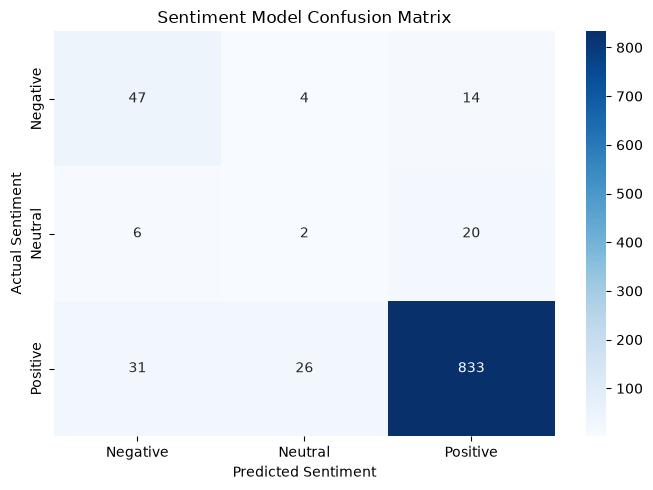

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "neutral", "positive"]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)
plt.title("Sentiment Model Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
joblib.dump(model, OUTPUT_DIR / "sentiment_model.joblib")
joblib.dump(vectorizer, OUTPUT_DIR / "tfidf_vectorizer.joblib")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [ ]:
def predict_sentiment(review):
    review_tfidf = vectorizer.transform([review])
    prediction = model.predict(review_tfidf)[0]
    return prediction

reviews = [
    "This product is amazing and I love it",
    "Very poor quality, I am disappointed",
    "The product is okay, nothing special"
]

for review in reviews:
    print("Review:", review)
    print("Predicted sentiment:", predict_sentiment(review))
    print()

Review: This product is amazing and I love it
Predicted sentiment: positive

Review: Very poor quality, I am disappointed
Predicted sentiment: positive

Review: The product is okay, nothing special
Predicted sentiment: positive



In [ ]:
import json

accuracy = accuracy_score(y_test, y_pred)

metrics = {
    "accuracy": round(float(accuracy), 4),
    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),
    "sentiment_classes": sorted(y.unique().tolist())
}

with open(OUTPUT_DIR / "model_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

pd.DataFrame({
    "Actual Sentiment": y_test.reset_index(drop=True),
    "Predicted Sentiment": y_pred
}).to_csv(OUTPUT_DIR / "sentiment_predictions.csv", index=False)

print("Evaluation results saved successfully!")
print(metrics)

Evaluation results saved successfully!
{'accuracy': 0.8973, 'training_samples': 3929, 'testing_samples': 983, 'sentiment_classes': ['negative', 'neutral', 'positive']}
